<a href="https://colab.research.google.com/github/baektaehee1026-ui/26-2-DIP-Baektaehee-202401846-/blob/main/HW01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###실습코드00

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
base_path = '/content/drive/MyDrive/'
ct_base= nib.load(base_path + 'volume-covid19-A-0700_day000.nii.gz').get_fdata()
ct_FU = nib.load(base_path +'volume-covid19-A-0700_day015.nii.gz').get_fdata()
ct_FU_reg = nib.load(base_path +'volume-covid19-A-0700_day015-reg_to_day000.nii.gz').get_fdata()

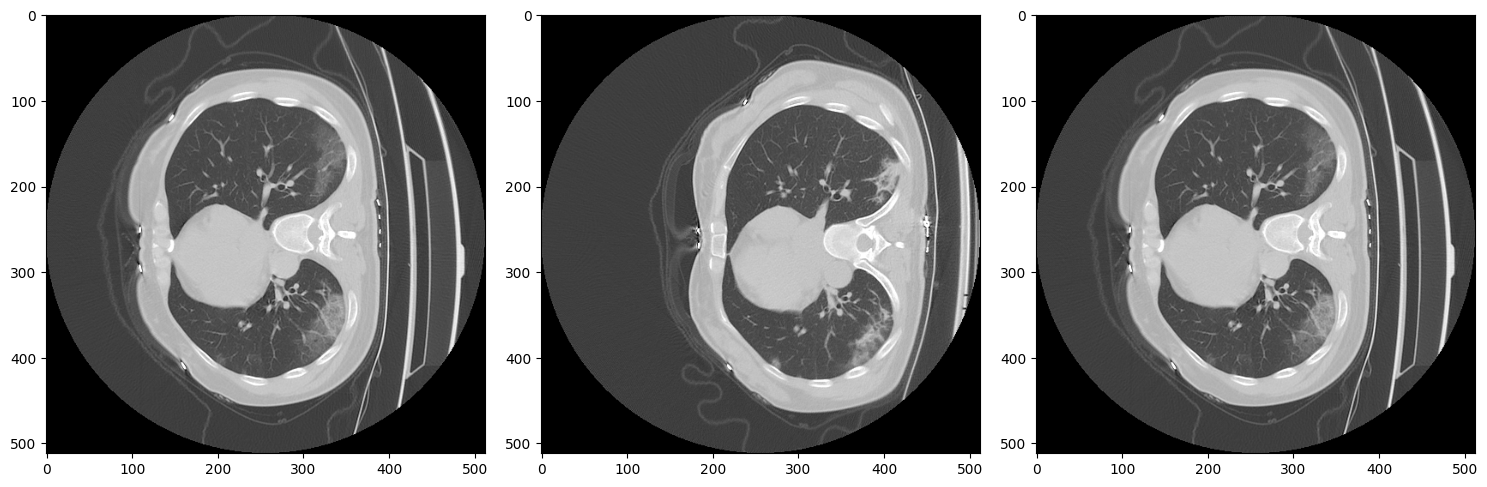

In [7]:
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_FU[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()

###Exercise1. local histogram equalization을 통해 숨겨진 패턴 확인하기

In [10]:
import os
imgpath = '/content/drive/MyDrive/DIP4E/DIP4E'
os.listdir(imgpath)

['numbers.tif',
 'Fig81c.tif',
 'four-squares.tif',
 'test-pattern-gaussian-noise.tif',
 'WashingtonDC-Band4-NearInfrared-564.tif',
 'cktboard-controller.tif',
 'Fig81b.tif',
 'letterA-distorted.tif',
 'GT.tif',
 'americas-at-night4.tif',
 'turbineblad-with-blk-dot.tif',
 'polymercell.tif',
 'wingding-circle-solid.tif',
 'galaxy-pair.tif',
 'bonescan-back.tif',
 'glass-caster-RGB.tif',
 'matches-aligned.tif',
 'painting.tif',
 'angiography-mask-image.tif',
 'lenna-RGB.tif',
 'lenna-gray.tif',
 'strip-uniform-noise.tif',
 'RGB-color-cube.tif',
 'americas-at-night3.tif',
 'washingtonDC-Band6-ThermalInfrared-512.tif',
 'edge-roof.tif',
 'dowels.tif',
 'phobos.tif',
 'hurricane-katrina-eye.tif',
 'chromosome.tif',
 'crabpulsar-optical.tif',
 'mammogram.tif',
 'sinePulses.tif',
 'circuitboard-pepper.tif',
 'calculator-binary.tif',
 'hubble.tif',
 'blurry-moon.tif',
 'OpticalMicroscope-superconductor-smooth-texture.tif',
 'WashingtonDC-RGBfrom-Bands-4-2-1.tif',
 'book-cover-gaussian.tif',
 '

In [15]:
def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_image

In [12]:
f = plt.imread(imgpath+'/hidden-symbols.tif')
print(f.shape,f.dtype)

(256, 256) uint8


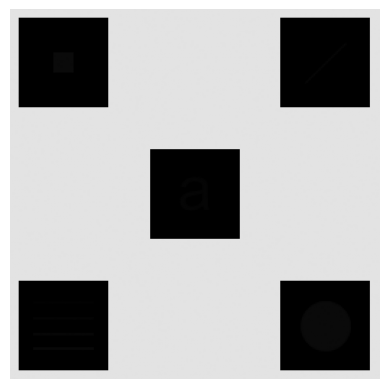

In [13]:
plt.imshow(f,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

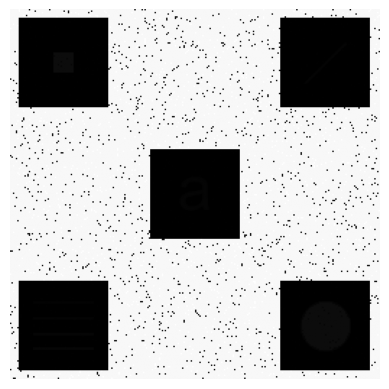

In [16]:
f_eq = histogram_equalization(f)
plt.imshow(f_eq,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

/tmp/ipykernel_650/3935879381.py:6: RuntimeWarning: invalid value encountered in divide
  cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
/tmp/ipykernel_650/3935879381.py:7: RuntimeWarning: invalid value encountered in cast
  cdf_normalized = cdf_normalized.astype(np.uint8)


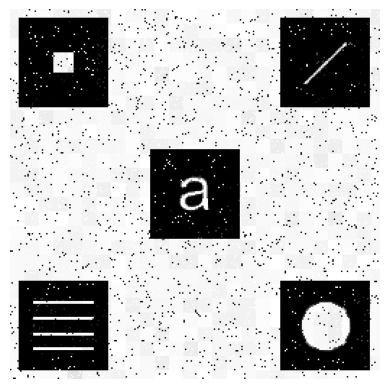

In [21]:
N =10
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

###Exercise2. 본인의 사진은 grayscale image로 불러온 후, 서로 다른 kernel size에 대한 LPF 결과 비교

In [23]:
import scipy.signal as signal
from skimage import io

In [24]:
f = io.imread(base_path + 'practice_photo.jpg',as_gray=True)[::2,::2]
print(f.shape,f.dtype)

(207, 368) float64


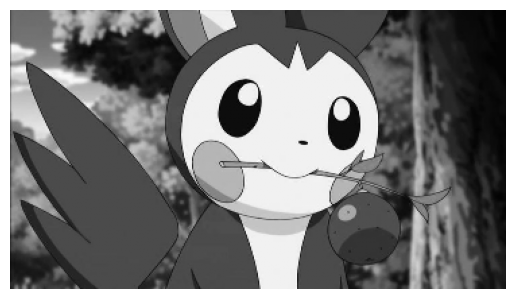

In [25]:
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.show()

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


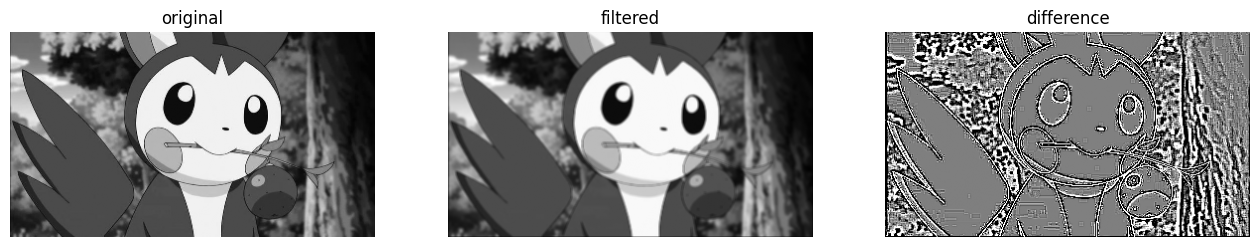

In [26]:
w = np.ones((3,3))
w = w/np.sum(w)
print(w)
yb = signal.convolve2d(f,w,mode='same')
plt.figure(figsize=(16,9))
plt.subplot(1,3,1)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('original')
plt.subplot(1,3,2)
plt.imshow(yb,cmap='gray')
plt.axis('off')
plt.title('filtered')
plt.subplot(1,3,3)
plt.imshow(yb-f,cmap='gray',vmin=-.01,vmax=.01)
plt.axis('off')
plt.title('difference')
plt.show()

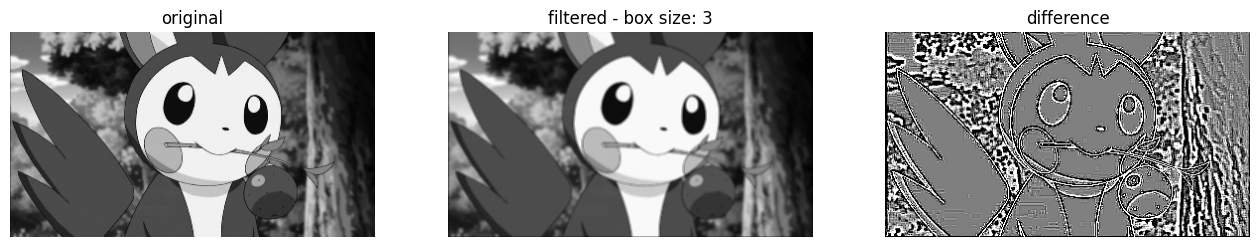

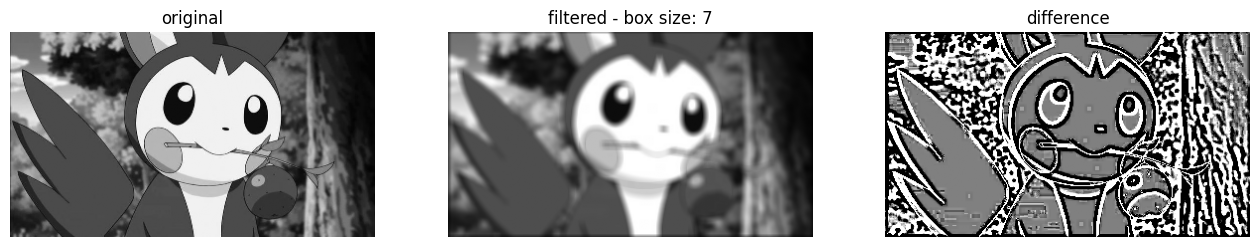

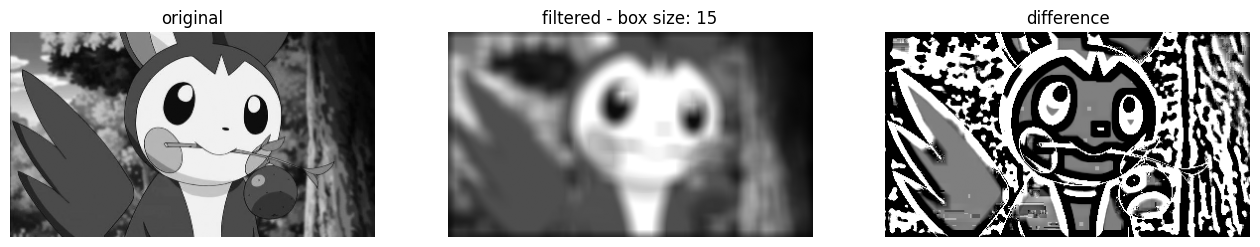

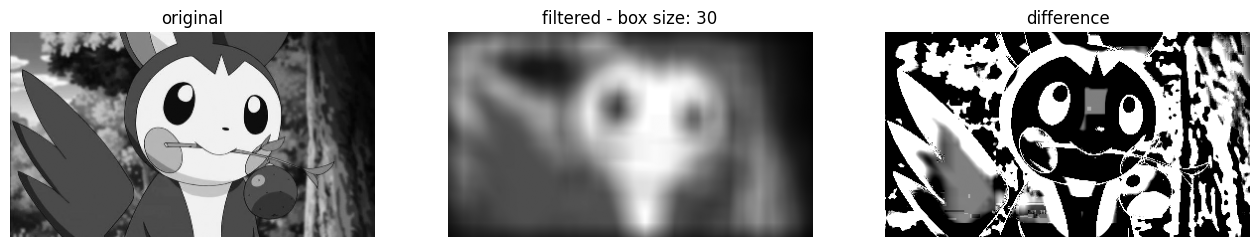

In [27]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  y_b = signal.convolve2d(f,wb,mode='same')

  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

  #box kernel

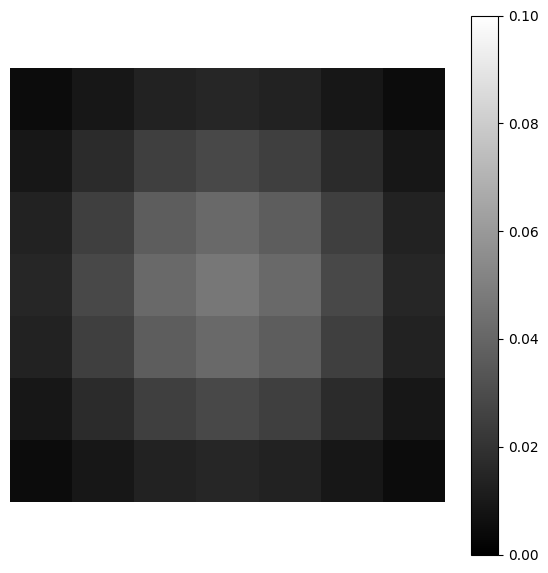

In [28]:
N = 3
std = 2
s = np.arange(-N,N+1,1)
t = np.arange(-N,N+1,1)
S,T = np.meshgrid(s,t)
wg = np.exp(-(S**2+T**2)/(2*std*std))
wg = wg/np.sum(wg)

plt.figure(figsize=(7,7))
plt.imshow(wg,vmin=0,vmax=0.1,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

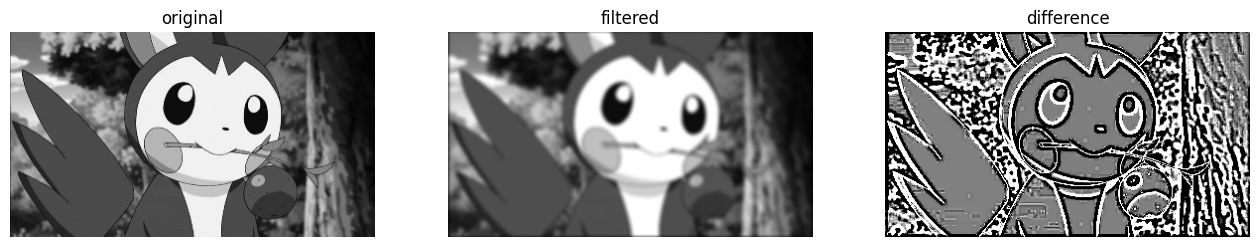

In [29]:
y_g = signal.convolve2d(f,wg,mode='same')

plt.figure(figsize=(16,9))
plt.subplot(1,3,1)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('original')
plt.subplot(1,3,2)
plt.imshow(y_g,cmap='gray')
plt.axis('off')
plt.title('filtered')
plt.subplot(1,3,3)
plt.imshow(y_g-f,cmap='gray',vmin=-.01,vmax=.01)
plt.axis('off')
plt.title('difference')
plt.show()

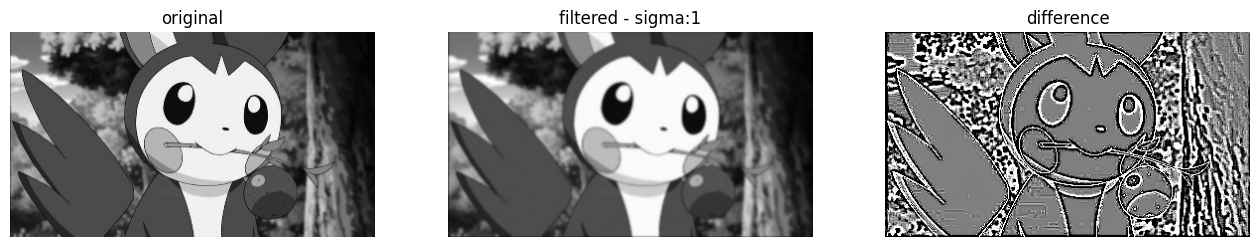

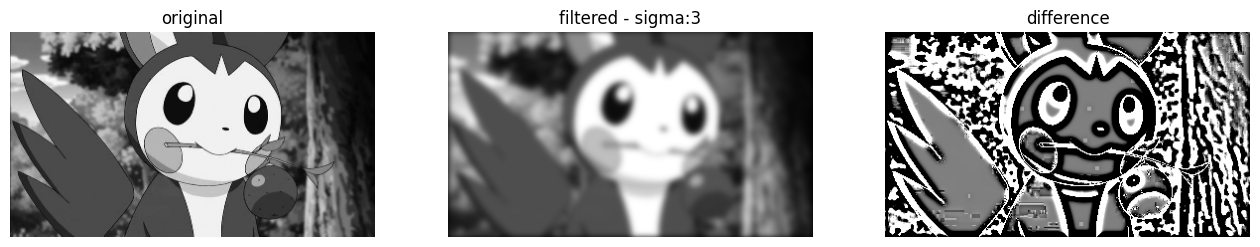

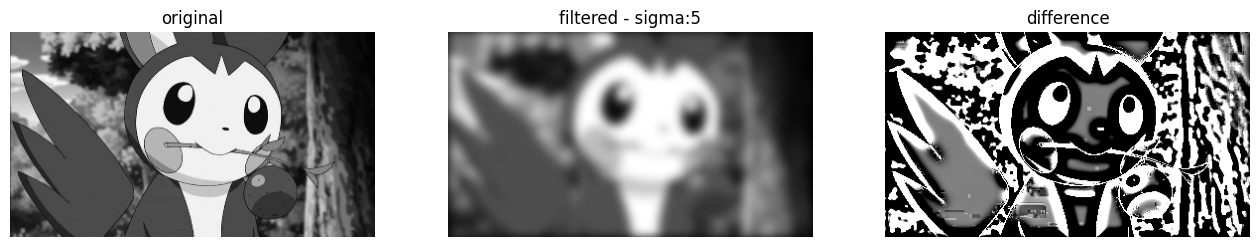

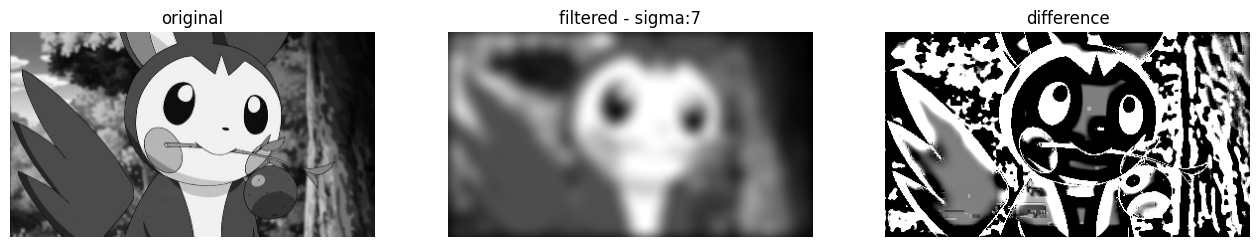

In [30]:
s = np.arange(-13,14,1)
t = np.arange(-13,14,1)
S,T = np.meshgrid(s,t)

for std in np.array([1,3,5,7]):
  wg = np.exp(-(S**2+T**2)/(2*std*std))
  wg = wg/np.sum(wg)

  y_g = signal.convolve2d(f,wg,mode='same')

  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_g,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - sigma:{std}')
  plt.subplot(1,3,3)
  plt.imshow(y_g-f,cmap='gray',vmin=-.01, vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

In [31]:
import time

computation time =  0.003945827484130859  sec


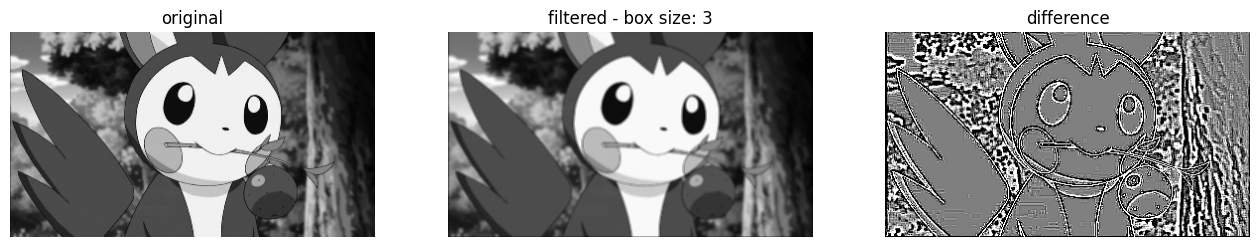

computation time =  0.011272907257080078  sec


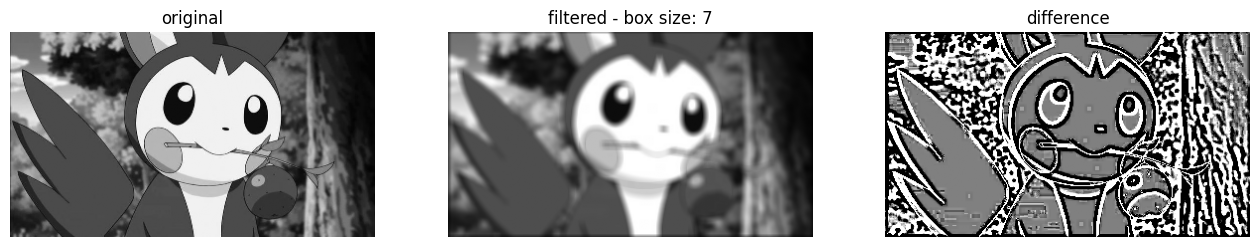

computation time =  0.0422368049621582  sec


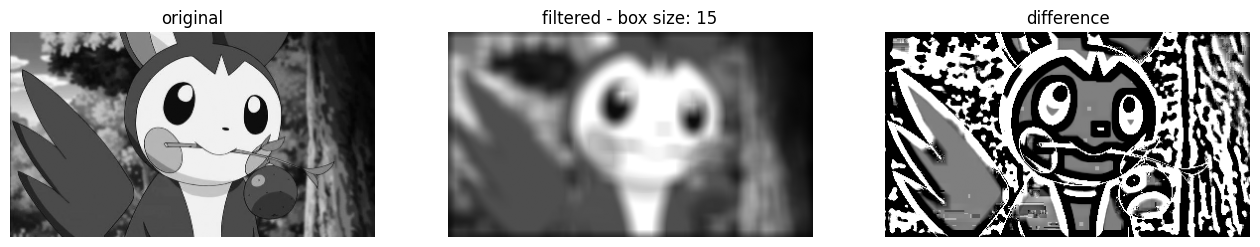

computation time =  0.14663243293762207  sec


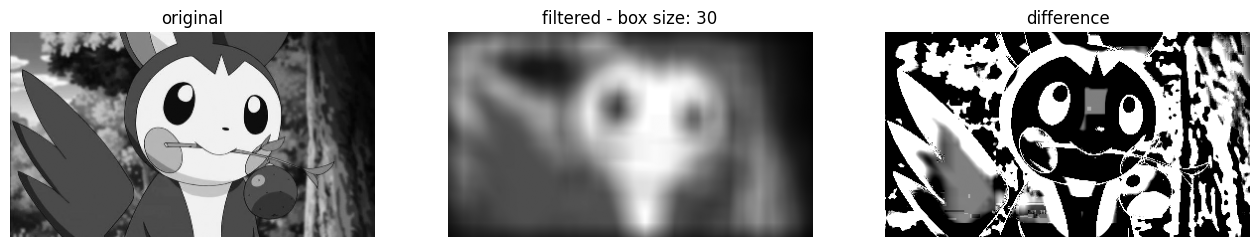

In [32]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

###Exercise 3. Blurring image로 HPF 결과를 활용한 sharpening

(600, 508) float64


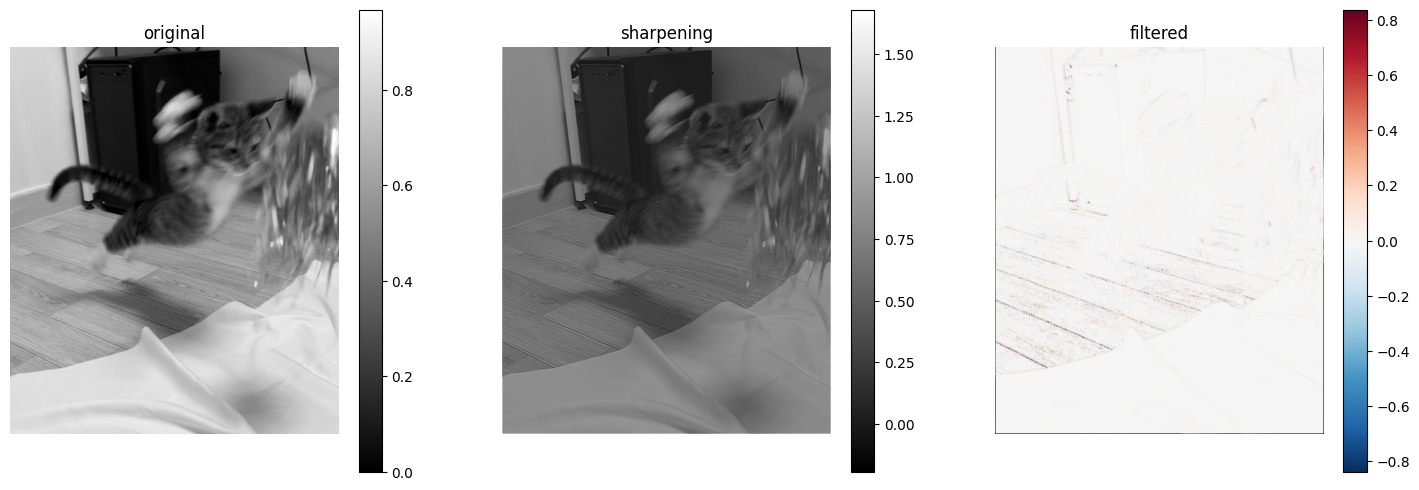

In [49]:
f = io.imread(base_path + 'blurring_image.jpg',as_gray=True)[::2,::2]
print(f.shape,f.dtype)
w = np.array([[0,-1,0],[-1,4.,-1],[0,-1,0]])
y = signal.convolve2d(f,w,mode='same')
c = 0.5
g = f + c*(y)
plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('sharpening')
plt.subplot(133)
plt.imshow(y,cmap='RdBu_r',vmin=-0.5*np.max(np.abs(y)),vmax=0.5*np.max(np.abs(y)))
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()

In [40]:
sobel1 = np.array([[-1,-2,-1],[0,0,0],[1,2,1]])
sobel2 = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
print(sobel1)
print(sobel2)

[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]
[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]


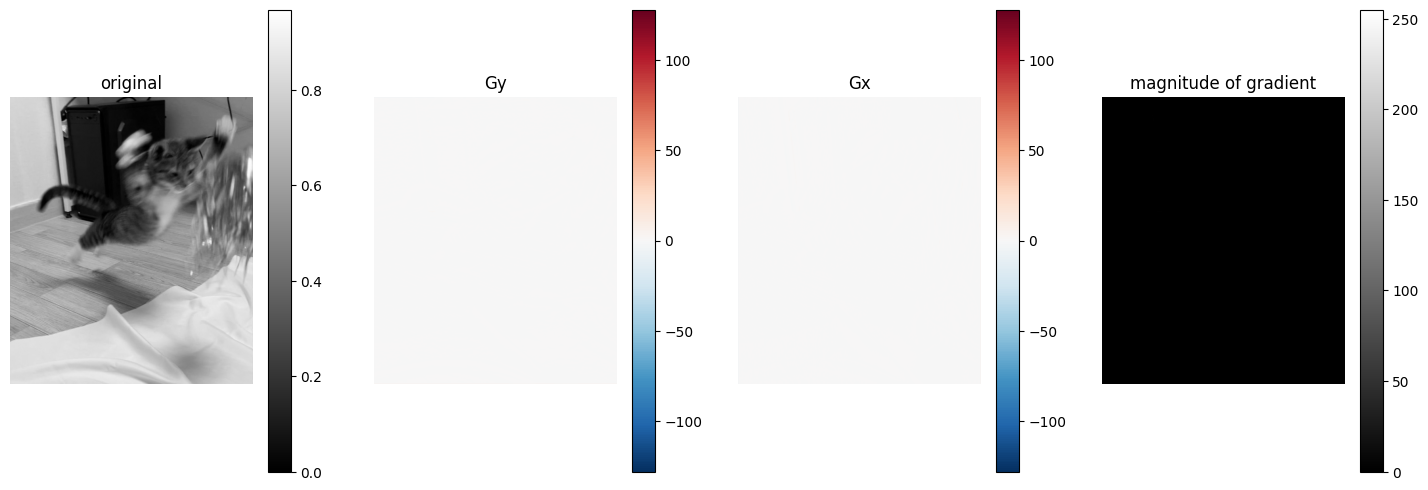

In [41]:
g1 = signal.convolve2d(f,sobel1,mode='same')
g2 = signal.convolve2d(f,sobel2,mode='same')
G = np.sqrt(g1**2+g2**2)

plt.figure(figsize=(18,6))
plt.subplot(141)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(142)
plt.imshow(g1,cmap='RdBu_r',vmin=-128,vmax=128)
plt.colorbar()
plt.axis('off')
plt.title('Gy')
plt.subplot(143)
plt.imshow(g2,cmap='RdBu_r',vmin=-128,vmax=128)
plt.colorbar()
plt.axis('off')
plt.title('Gx')
plt.subplot(144)
plt.imshow(G,cmap='gray',vmin=0,vmax=255)
plt.colorbar()
plt.axis('off')
plt.title('magnitude of gradient')
plt.show()

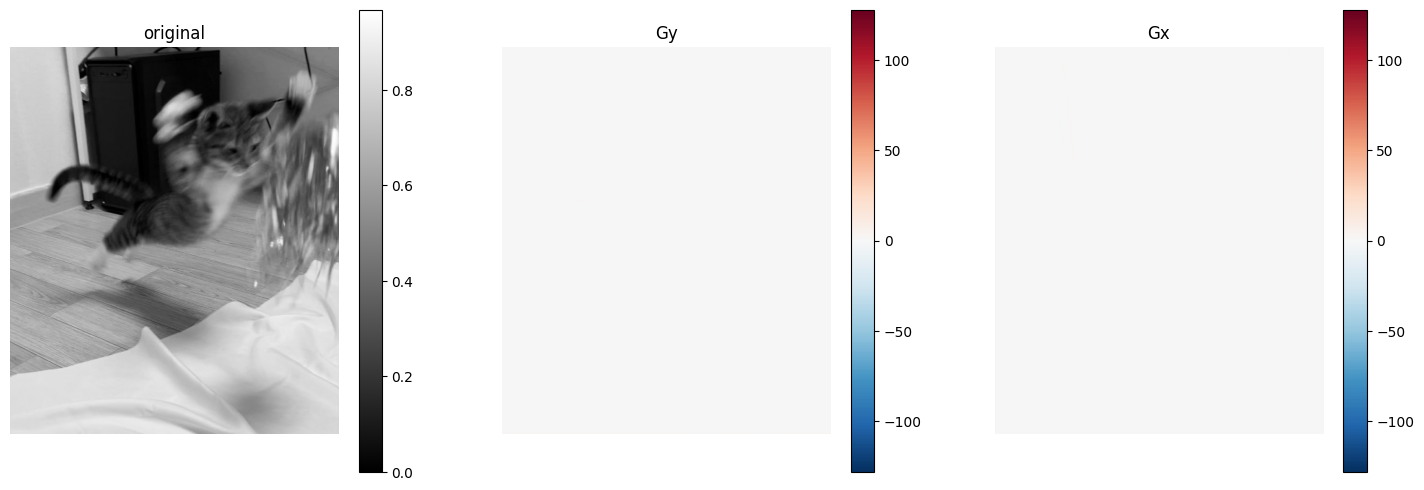

In [44]:
f = io.imread(base_path + 'blurring_image.jpg',as_gray=True)[::2,::2]
g1 = signal.convolve2d(f,sobel1,mode='same')
g2 = signal.convolve2d(f,sobel2,mode='same')
G = np.sqrt(g1**2+g2**2)

plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g1,cmap='RdBu_r',vmin=-128,vmax=128)
plt.colorbar()
plt.axis('off')
plt.title('Gy')
plt.subplot(133)
plt.imshow(g2,cmap='RdBu_r',vmin=-128,vmax=128)
plt.colorbar()
plt.axis('off')
plt.title('Gx')
plt.show()

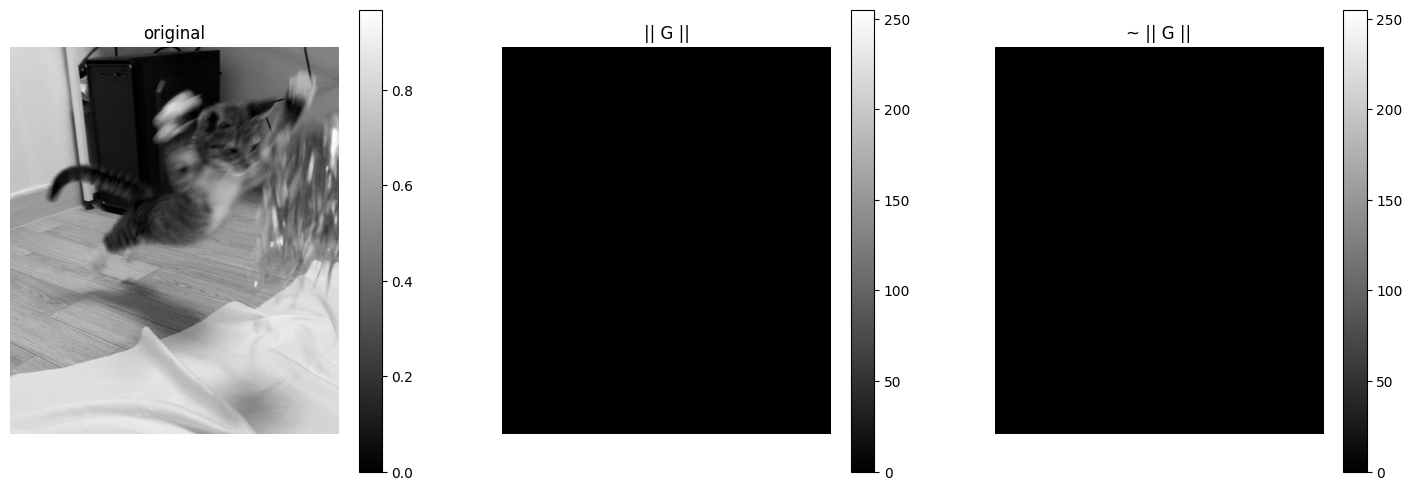

In [45]:
G_ = np.abs(g1) + np.abs(g2)
plt.figure(figsize=(18,6))

plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')

plt.subplot(132)
plt.imshow(G,cmap='gray',vmin=0,vmax=255)
plt.colorbar()
plt.axis('off')
plt.title('|| G ||')

plt.subplot(133)
plt.imshow(G_,cmap='gray',vmin=0,vmax=255)
plt.colorbar()
plt.axis('off')
plt.title('~ || G ||')

plt.show()